<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/Single_CPW_Resonator_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# Single CPW Hanger Resonator

Quantum Metal builds a coplanar waveguide (CPW) feedline between two wirebond launchpads on a 10 × 8 mm chip, in which a native `CoupledLineTee` couples the feedline to a meandered resonator. The coupler arm holds an open end, while a native `ShortToGround` terminates the far end of the `RouteMeander` and supplies the open-short boundary conditions of a quarter-wave hanger.

## Layout parameters

| Parameter | Value or Quantum Metal option |
| --- | --- |
| Chip X size (`CHIP_SIZE_X`) | 10 mm |
| Chip Y size (`CHIP_SIZE_Y`) | 8 mm |
| GDS layer | 1, positive ground and conductors |
| CPW trace width and gap | 10 µm and 6 µm |
| Feedline center (`FEEDLINE_Y`) | $y=1.5$ mm |
| Launchpad pins (`LAUNCHER_X`) | $x=pm4$ mm, $y=1.5$ mm |
| Launchpad geometry | Width 160 µm, body length 200 µm, taper 200 µm, lead 25 µm, gap 58 µm |
| Launchpad orientations | Input: 0°; output: 180° |
| Coupler position and orientation | $(0,1.5)$ mm, 0°, `mirror=False` |
| Coupler | Length 320 µm, secondary exit length 300 µm, circular fillet radius 50 µm |
| Coupler ground strip | `coupling_space=6um`, between the two CPW gap boundaries |
| Feedline-to-resonator metal edge separation | $6+6+6=18$ µm |
| Coupler termination | `open_termination=True` |
| Meander length (`RESONATOR_ROUTE_LENGTH`) | 6.4 mm, including circular bends |
| Resonator circular fillet radius | 80 µm |
| Resonator leads | 250 µm at each endpoint |
| Meander spacing and asymmetry | 400 µm and 0 µm |
| Short distance below feedline (`RESONATOR_TIP_DISTANCE`) | 3000 µm |
| Grounded resonator end | `ShortToGround`, $(0.160,-1.500)$ mm, orientation 270° |
| Ground-plane cheesing | Native 25 × 25 µm square holes, 100 µm center-to-center pitch |
| Cheese keep-out | Native 25 µm component buffer; hole boundaries stay at least 100 µm inside every chip edge |
| GDS precision | 1 nm |

Here, the meander length $\ell_m$ and the coupler-arm length $\ell_c$ combine into the resonator centerline length $\ell$, in which both lengths include their circular-bend corrections.

$$
\ell=\ell_m+\ell_c=6.400000\,\mathrm{mm}+0.598540\,\mathrm{mm}=6.998540\,\mathrm{mm}.
$$

The 6.4 mm control sets the meander and the length table includes the coupler arm separately.

## API documentation

[Quantum Metal installation](https://qiskit-community.github.io/qiskit-metal/installation.html) · [Coupled-line tee options](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.CoupledLineTee.html) · [Native meander routing](https://qiskit-community.github.io/qiskit-metal/tut/2-From-components-to-chip/2.12-Simple-Meander.html) · [Built-in cheesing and keep-out options](https://qiskit-community.github.io/qiskit-metal/tut/3-Renderers/3.2-Export-your-design-to-GDS.html)

In [ ]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!uv pip install -q quantum-metal

In [ ]:
"""This script builds a single CPW hanger resonator in Quantum Metal."""

# --- Control Knobs ---
CHIP_SIZE_X = "10mm"
CHIP_SIZE_Y = "8mm"
FEEDLINE_Y = "1.5mm"
LAUNCHER_X = "4mm"
RESONATOR_ROUTE_LENGTH = "6.4mm"
RESONATOR_TIP_DISTANCE = "3000um"
METAL_LAYER = 1
OUTPUT_FILENAME = "single_cpw_resonator.gds"

# --- Imports and Design ---
import logging
import os
from importlib.metadata import version
from pathlib import Path

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

import gdstk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit_metal as qm
from IPython.display import FileLink, display
from matplotlib.collections import PolyCollection
from qiskit_metal import Dict, designs
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.terminations.short_to_ground import ShortToGround
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer
from qiskit_metal.validation import validate

plt.rcParams["figure.dpi"] = 250

design = designs.DesignPlanar(overwrite_enabled=True, enable_renderers=False)
design.chips.main.size.size_x = CHIP_SIZE_X
design.chips.main.size.size_y = CHIP_SIZE_Y
design.variables.cpw_width = "10um"
design.variables.cpw_gap = "6um"
gds_renderer = QGDSRenderer(design)
design.renderers.gds = gds_renderer
launchpads, feedlines = [], []
print(f"Quantum Metal {version('quantum-metal')}")

Quantum Metal 0.9.0


In [ ]:
# --- Wirebond Launchpads and Hanger Coupler ---
for name, sign, angle in (("LP_IN", -1, 0), ("LP_OUT", 1, 180)):
    launchpads.append(LaunchpadWirebond(
        design, name,
        options=Dict(
            pos_x=f"{sign * design.parse_value(LAUNCHER_X)}mm",
            pos_y=FEEDLINE_Y, orientation=str(angle), layer=str(METAL_LAYER),
            trace_width="10um", trace_gap="6um", lead_length="25um",
            pad_width="160um", pad_height="200um", pad_gap="58um",
            taper_height="200um",
        ),
    ))

coupler = CoupledLineTee(
    design, "HANGER_COUPLER",
    options=Dict(
        pos_x="0mm", pos_y=FEEDLINE_Y, orientation="0", layer=str(METAL_LAYER),
        prime_width="10um", prime_gap="6um", second_width="10um", second_gap="6um",
        coupling_length="320um", coupling_space="6um", down_length="300um",
        fillet="50um", mirror=False, open_termination=True,
    ),
)

# --- Feedline ---
for name, start_component, start_pin, end_component, end_pin in (
    ("FEED_LEFT", "LP_IN", "tie", coupler.name, "prime_start"),
    ("FEED_RIGHT", coupler.name, "prime_end", "LP_OUT", "tie"),
):
    feedlines.append(RouteStraight(
        design, name,
        options=Dict(
            layer=str(METAL_LAYER), trace_width="10um", trace_gap="6um",
            pin_inputs=Dict(
                start_pin=Dict(component=start_component, pin=start_pin),
                end_pin=Dict(component=end_component, pin=end_pin),
            ),
        ),
    ))

# --- Grounded Resonator End and Native Meander ---
short_y_mm = (
    design.parse_value(FEEDLINE_Y) - design.parse_value(RESONATOR_TIP_DISTANCE)
)
short = ShortToGround(
    design, "RESONATOR_SHORT",
    options=Dict(
        pos_x=f"{coupler.pins.second_end.middle[0]}mm",
        pos_y=f"{short_y_mm}mm",
        orientation="270", layer=str(METAL_LAYER), width="10um",
    ),
)

resonator = RouteMeander(
    design, "HANGER_RESONATOR",
    options=Dict(
        layer=str(METAL_LAYER), trace_width="10um", trace_gap="6um",
        pin_inputs=Dict(
            start_pin=Dict(component=coupler.name, pin="second_end"),
            end_pin=Dict(component=short.name, pin="short"),
        ),
        total_length=RESONATOR_ROUTE_LENGTH, fillet="80um",
        lead=Dict(start_straight="250um", end_straight="250um"),
        meander=Dict(spacing="400um", asymmetry="0um"),
        prevent_short_edges="true", snap="true",
    ),
)

# --- Geometry and Length Checks ---
assert abs(resonator.length - design.parse_value(RESONATOR_ROUTE_LENGTH)) < 1e-5
chip_bounds, chip_status = design.get_x_y_for_chip("main")
assert chip_status == 0
for component in design.components.values():
    assert component.status == "good", component.name
    # ShortToGround supplies a pin without adding mask polygons.
    if component is short:
        continue
    xmin, ymin, xmax, ymax = component.qgeometry_bounds()
    assert xmin >= chip_bounds[0] and ymin >= chip_bounds[1], component.name
    assert xmax <= chip_bounds[2] and ymax <= chip_bounds[3], component.name
for table_name in ("poly", "path"):
    table = design.qgeometry.tables[table_name]
    assert table.geometry.is_valid.all(), table_name
    assert not table.geometry.is_empty.any(), table_name
drc = validate(design)
drc.raise_if_errors()
print(drc.report())

secondary = coupler.qgeometry_table("path")
secondary = secondary[secondary.name == "second_cpw"].iloc[0]
coupler_length_mm = (
    secondary.geometry.length - (2 - np.pi / 2) * float(secondary.fillet)
)
display(pd.DataFrame([{
    "meander_mm": resonator.length,
    "coupler_arm_mm": coupler_length_mm,
    "total_centerline_mm": resonator.length + coupler_length_mm,
    "tip_from_feedline_mm": (
        design.parse_value(FEEDLINE_Y) - short.pins.short.middle[1]
    ),
}]).round(6))
print(f"1 hanger resonator; {len(launchpads)} launchpads; "
      f"{len(feedlines)} feedline routes")

Design rules passed (11 rules ran, no findings).
1 hanger resonator; 2 launchpads; 2 feedline routes


,meander_mm,coupler_arm_mm,total_centerline_mm,tip_from_feedline_mm
0,6.4,0.59854,6.99854,3.0


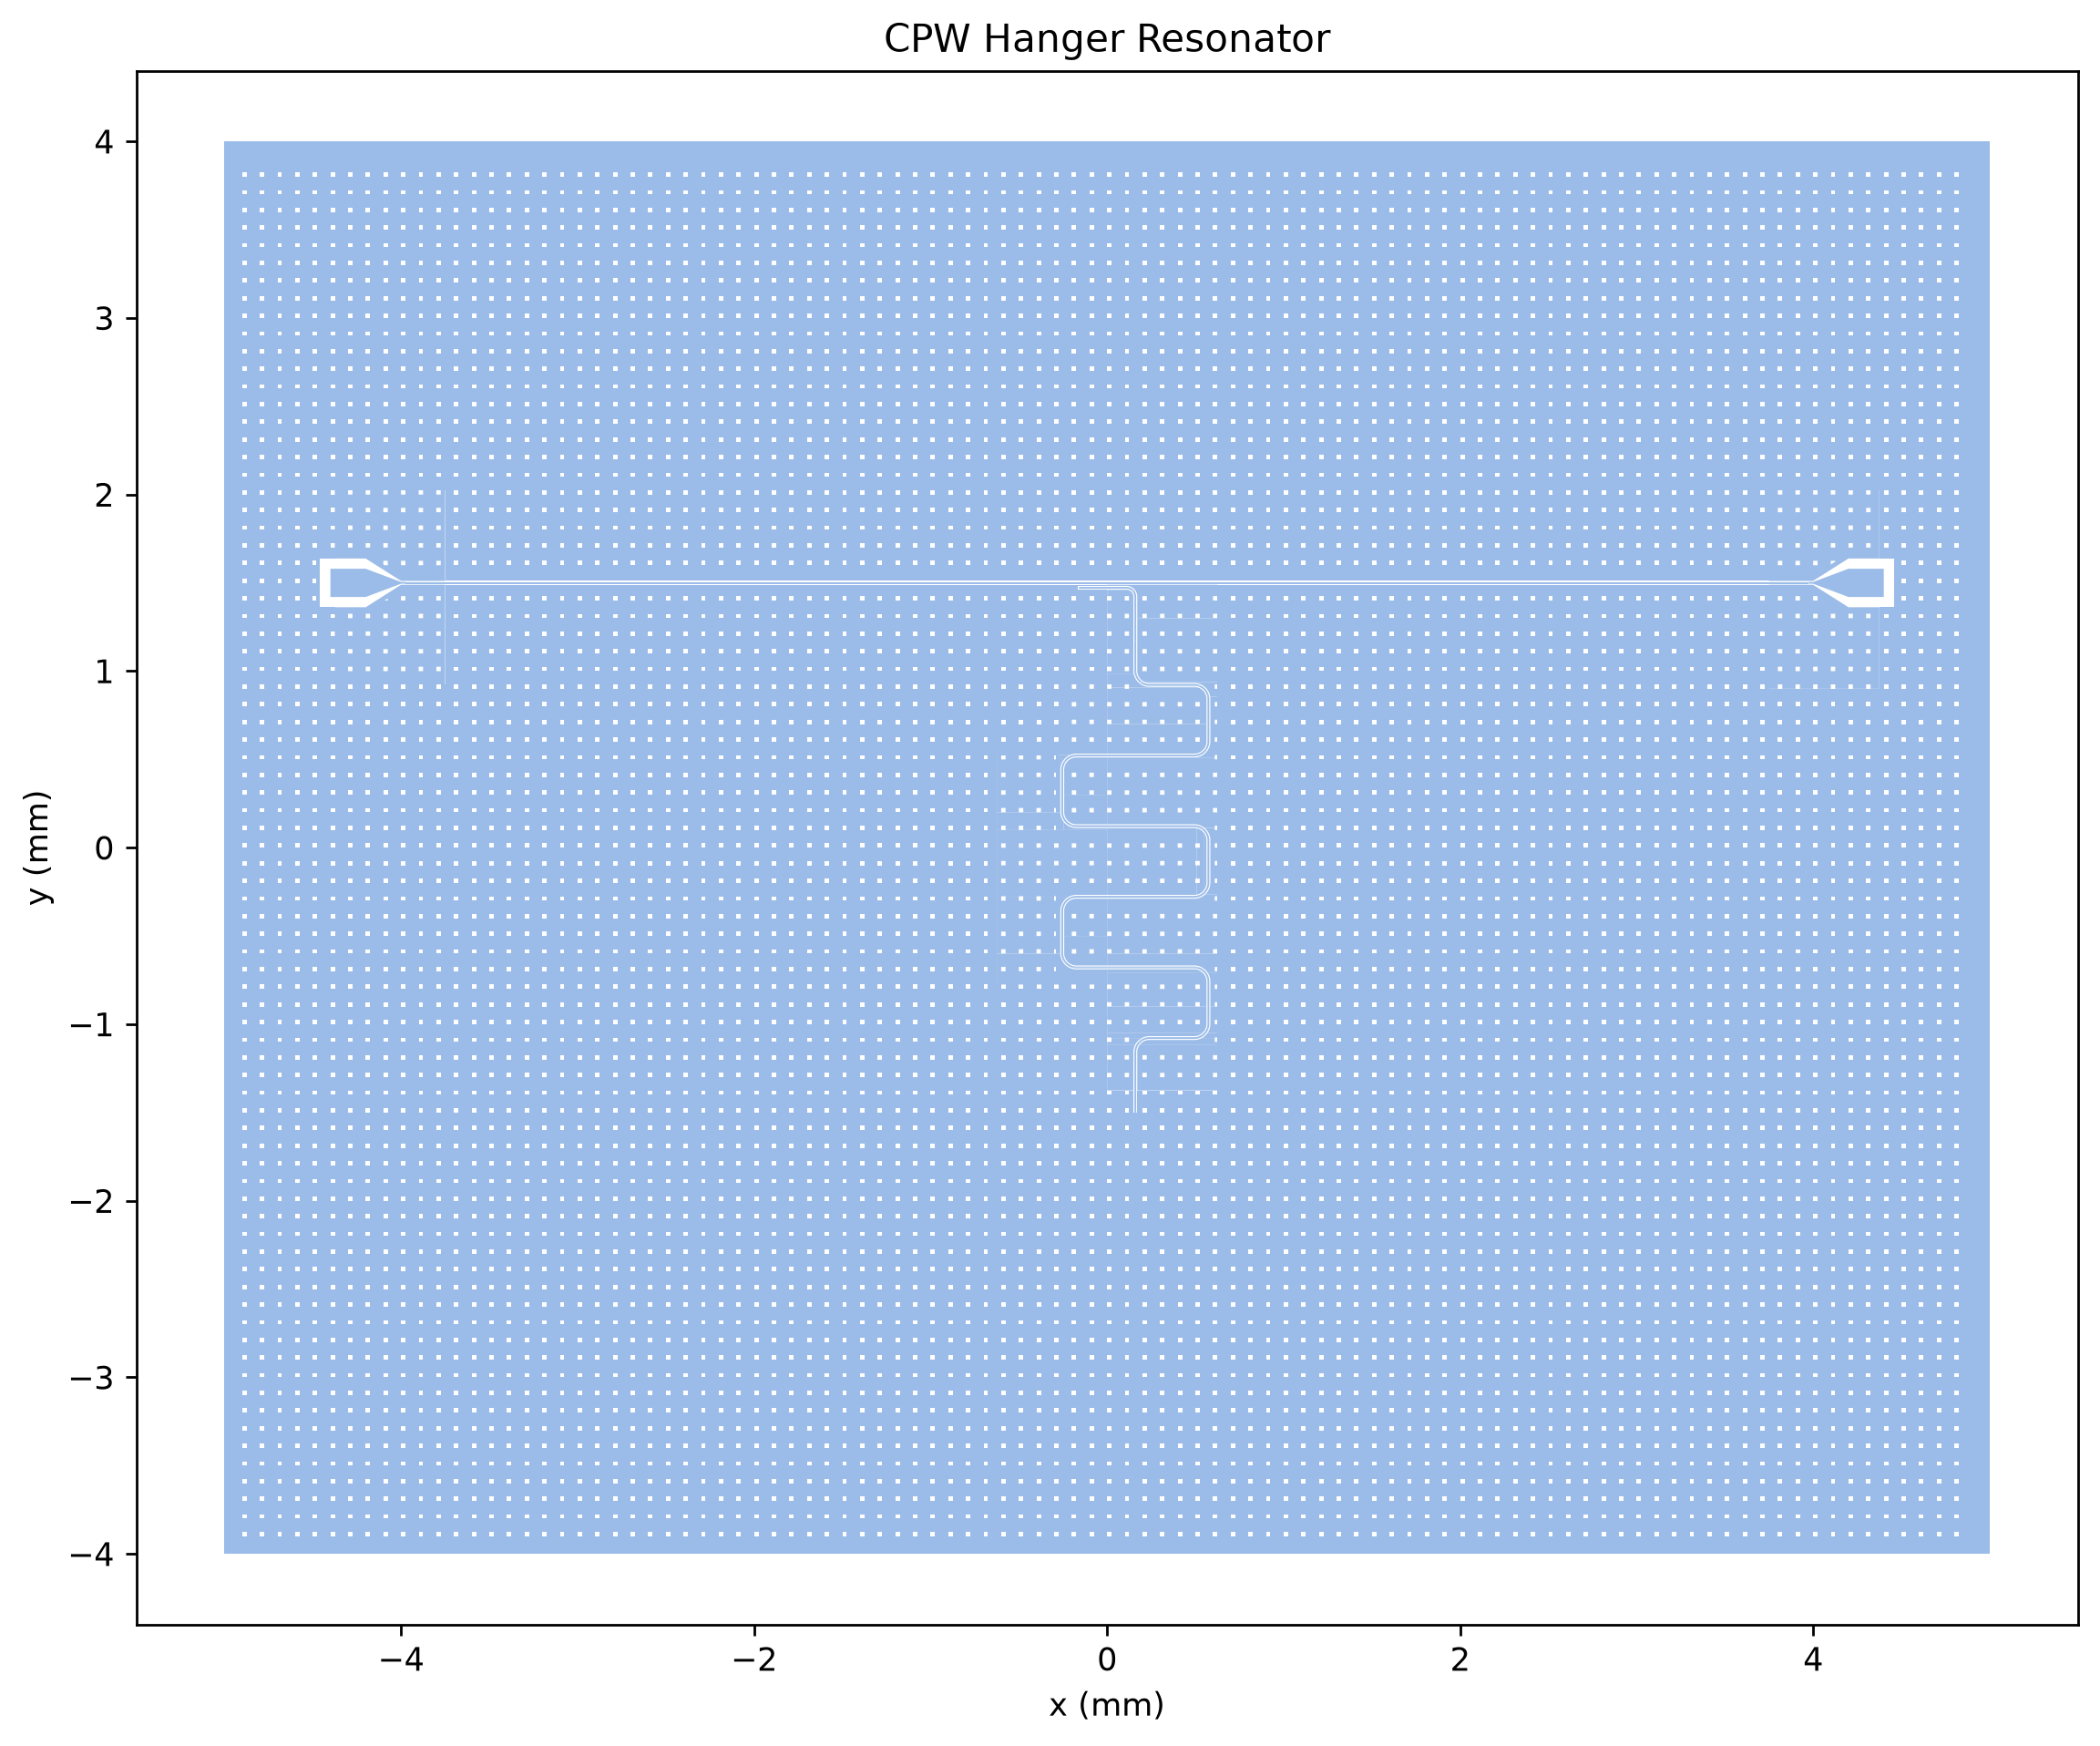

GDSII: single_cpw_resonator.gds (421,658 bytes)
Layer 1: ground, feedline, launchpads, and hanger resonator


/workspace/scratch/e66d3684c295/single_cpw_quantum_metal/single_cpw_resonator.gds

In [ ]:
# --- Native Cheesing and GDS Export ---
out = Path.cwd() / OUTPUT_FILENAME
gds_renderer.options.precision = "1e-9"
gds_renderer.options.tolerance = "1e-6"
gds_renderer.options.fabricate = "True"
gds_renderer.options.short_segments_to_not_fillet = "False"
gds_renderer.options.path_filename = ""

gds_renderer.options.cheese = QGDSRenderer.default_options.cheese.copy()
# Hole-center inset = 100 um edge clearance + half the default 25 um hole width.
gds_renderer.options.cheese.edge_nocheese = "112.5um"
gds_renderer.options.cheese.view_in_file = Dict(main={METAL_LAYER: True})
gds_renderer.options.no_cheese.view_in_file = Dict(main={METAL_LAYER: False})

previous_log_level = qm.logger.level
qm.logger.setLevel(logging.ERROR)
try:
    export_status = gds_renderer.export_to_gds(str(out))
finally:
    qm.logger.setLevel(previous_log_level)
assert export_status and out.is_file() and out.stat().st_size > 0

# Keep references only to cells present in the exported library.
cell_names = {cell.name for cell in gds_renderer.lib.cells}
for cell in gds_renderer.lib.cells:
    for reference in list(cell.references):
        if reference.cell_name not in cell_names:
            cell.remove(reference)
gds_renderer.lib.write_gds(str(out))

# --- Export Checks ---
verified_gds = gdstk.read_gds(str(out))
top_cells = verified_gds.top_level()
assert len(top_cells) == 1
exported_polygons = top_cells[0].get_polygons()
assert {polygon.layer for polygon in exported_polygons} == {METAL_LAYER}
assert np.isclose(verified_gds.precision, 1e-9)

# --- In-Memory GDS Preview ---
fig, ax = plt.subplots(figsize=(11, 9), dpi=250)
ax.add_collection(PolyCollection(
    [polygon.points for polygon in exported_polygons],
    facecolor="#9bbce8", edgecolor="none", rasterized=True,
))
ax.autoscale_view()
ax.set_aspect("equal")
ax.set(xlabel="x (mm)", ylabel="y (mm)", title="CPW Hanger Resonator")
plt.show()

print(f"GDSII: {out.name} ({out.stat().st_size:,} bytes)")
print(f"Layer {METAL_LAYER}: ground, feedline, launchpads, and hanger resonator")
display(FileLink(str(out)))